In [1]:
!pip -q install kaggle

import os, json, pathlib
token = {
    "username": "audoantrung",
    "key": "da33b10941aac9bf170cbc4a856ae0a8"
}

pathlib.Path("/root/.kaggle").mkdir(parents=True, exist_ok=True)
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(token, f)

!chmod 600 /root/.kaggle/kaggle.json
!kaggle datasets list -s galaxy | head -n 5



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
'chmod' is not recognized as an internal or external command,
operable program or batch file.
'head' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
# Khai báo đường dẫn lưu dataset
DEST="/content/jwst_raw"

# Tạo thư mục nếu chưa có
!mkdir -p "$DEST"

# Tải dataset về bằng Kaggle CLI
!kaggle kernels output meeratif/galaxy-and-nebula-images-by-james-web-telescope -p "$DEST"

# Nếu tải về là file .zip thì giải nén
!unzip -q "$DEST"/*.zip -d "$DEST" || true

# Kiểm tra cấu trúc thư mục
!find "$DEST" -maxdepth 2 -type d -print


The syntax of the command is incorrect.
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\User\AppData\Local\Programs\Python\Python312\Scripts\kaggle.exe\__main__.py", line 2, in <module>
  File "C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\kaggle\__init__.py", line 6, in <module>
    api.authenticate()
  File "C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\kaggle\api\kaggle_api_extended.py", line 434, in authenticate
    raise IOError('Could not find {}. Make sure it\'s located in'
OSError: Could not find kaggle.json. Make sure it's located in C:\Users\User\.kaggle. Or use the environment method. See setup instructions at https://github.com/Kaggle/kaggle-api/
'unzip' is not recognized as an internal or external command,
operable program or batch file.
'true' is not recognized as an internal or external command,
operable program 

In [3]:
import os

path = "/content/jwst_raw"
for root, dirs, files in os.walk(path):
    for f in files:
        print(os.path.join(root, f))


In [4]:
!pip -q install kaggle
import os, json, pathlib

# TẠO kaggle.json trực tiếp (đổi username/key của bạn vào đây nếu cần)
token = {"username":"<audoantrung>", "key":"<da33b10941aac9bf170cbc4a856ae0a8>"}
pathlib.Path("/root/.kaggle").mkdir(parents=True, exist_ok=True)
with open("/root/.kaggle/kaggle.json","w") as f: json.dump(token,f)
!chmod 600 /root/.kaggle/kaggle.json

# kiểm tra CLI hoạt động
!kaggle datasets list -s galaxy | head



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
'chmod' is not recognized as an internal or external command,
operable program or batch file.
'head' is not recognized as an internal or external command,
operable program or batch file.


In [5]:
DEST="/content/jwst_raw"
!mkdir -p "$DEST"
!kaggle datasets download -d jaimetrickz/galaxy-zoo-2-images -p "$DEST"


The syntax of the command is incorrect.
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\User\AppData\Local\Programs\Python\Python312\Scripts\kaggle.exe\__main__.py", line 6, in <module>
  File "C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\kaggle\cli.py", line 68, in main
    out = args.func(**command_args)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\kaggle\api\kaggle_api_extended.py", line 1741, in dataset_download_cli
    with self.build_kaggle_client() as kaggle:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\kaggle\api\kaggle_api_extended.py", line 688, in build_kaggle_client
    username=self.config_values['username'],
             ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
KeyError: 'username'


In [6]:
import os

for root, dirs, files in os.walk(DEST):
    for f in files:
        print(os.path.join(root, f))


In [7]:
import zipfile
import os

zip_path = "/content/jwst_raw/galaxy-zoo-2-images.zip"
extract_path = "/content/jwst_raw/galaxy-zoo-2-images"

# Giải nén
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Giải nén xong vào:", extract_path)


FileNotFoundError: [Errno 2] No such file or directory: '/content/jwst_raw/galaxy-zoo-2-images.zip'

In [ ]:
import zipfile

# Đường dẫn file zip đã tải về
zip_path = "/content/jwst_raw/galaxy-zoo-2-images.zip"
extract_path = "/content/jwst_raw/galaxy_zoo_2"

# Giải nén file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Giải nén xong vào:", extract_path)

# Kiểm tra lại số lượng ảnh
import glob
img_files = glob.glob(extract_path + "/**/*.jpg", recursive=True) + glob.glob(extract_path + "/**/*.png", recursive=True)
print("Tìm thấy", len(img_files), "ảnh")


Giải nén xong vào: /content/jwst_raw/galaxy_zoo_2
Tìm thấy 243434 ảnh


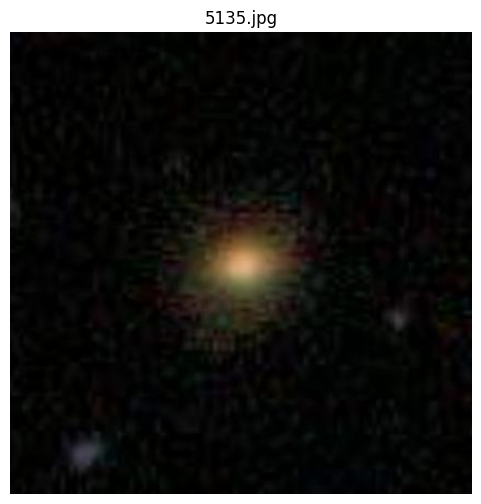

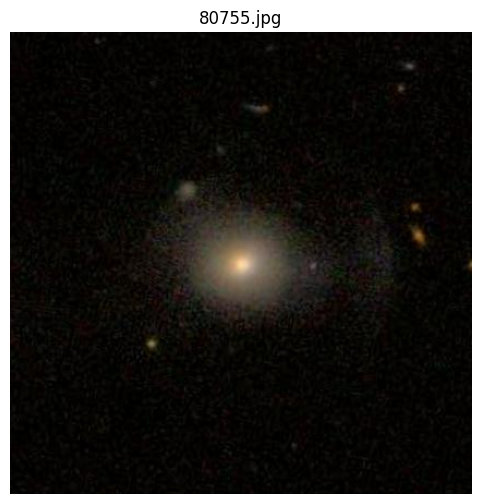

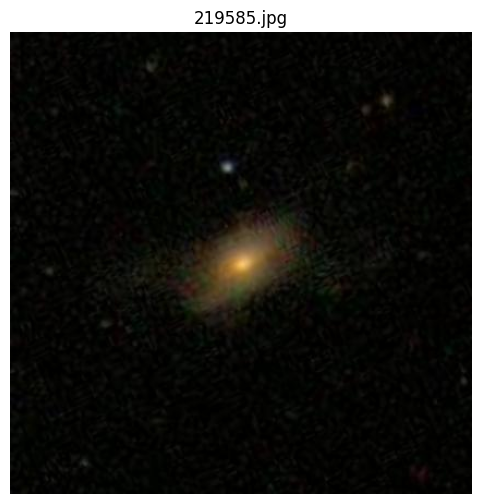

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os

for i in random.sample(img_files, 3):
    img = mpimg.imread(i)
    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(os.path.basename(i))
    plt.show()


In [ ]:
for root, dirs, files in os.walk(extract_path):
    for f in files[:10]:   # chỉ in thử 10 file đầu tiên
        print(os.path.join(root, f))
    break


/content/jwst_raw/galaxy_zoo_2/gz2_filename_mapping.csv


In [ ]:
import pandas as pd
import os

CSV_FILE = "/content/jwst_raw/galaxy-zoo-2-images/gz2_filename_mapping.csv"
labels = pd.read_csv(CSV_FILE)
labels.head()


,objid,sample,asset_id
0,587722981736120347,original,1
1,587722981736579107,original,2
2,587722981741363294,original,3
3,587722981741363323,original,4
4,587722981741559888,original,5


In [ ]:
labels.info()
labels.describe()
print(labels.columns)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 355990 entries, 0 to 355989
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   objid     355990 non-null  int64 
 1   sample    355990 non-null  object
 2   asset_id  355990 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 8.1+ MB
Index(['objid', 'sample', 'asset_id'], dtype='object')


In [ ]:
import os, glob, random

IMG_ROOT = "/content/jwst_raw/galaxy_zoo_2"   # thư mục ảnh bạn đã giải nén
img_files = glob.glob(os.path.join(IMG_ROOT, "**/*.jpg"), recursive=True)
print("Số ảnh:", len(img_files))
# Lấy mẫu nhỏ để chạy nhanh (ví dụ 10k ảnh). Có thể tăng/giảm tuỳ GPU.
N = min(10000, len(img_files))
img_files = random.sample(img_files, N)


Số ảnh: 243434


In [ ]:
import numpy as np, tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras import layers

IMG_SIZE = (224,224)
base = MobileNetV2(input_shape=IMG_SIZE+(3,), include_top=False, pooling="avg", weights="imagenet")

def embed_batch(paths):
    batch = []
    for p in paths:
        img = image.load_img(p, target_size=IMG_SIZE)
        x = image.img_to_array(img)
        batch.append(x)
    x = np.stack(batch).astype("float32")
    x = preprocess_input(x)
    emb = base.predict(x, verbose=0)
    return emb

# Trích đặc trưng theo lô để tránh OOM
BATCH=64
embeds = []
for i in range(0, len(img_files), BATCH):
    embeds.append(embed_batch(img_files[i:i+BATCH]))
embeds = np.vstack(embeds)
embeds.shape


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


(10000, 1280)

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# PCA cho nhanh + trực quan
pca = PCA(n_components=50, random_state=0)
X = pca.fit_transform(embeds)

# Số cụm: thử 3–6 cụm (tuỳ bạn); ở đây chọn 4
k = 4
kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
labels = kmeans.fit_predict(X)

print("Cỡ cụm:", {i:int((labels==i).sum()) for i in range(k)})


Cỡ cụm: {0: 2809, 1: 3787, 2: 1238, 3: 2166}


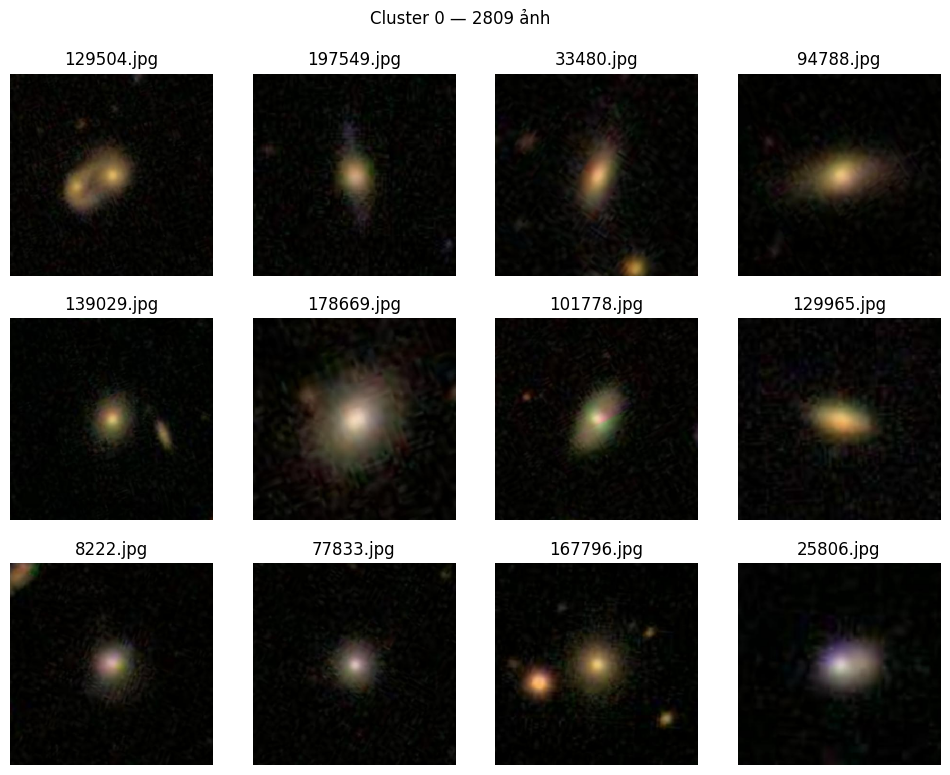

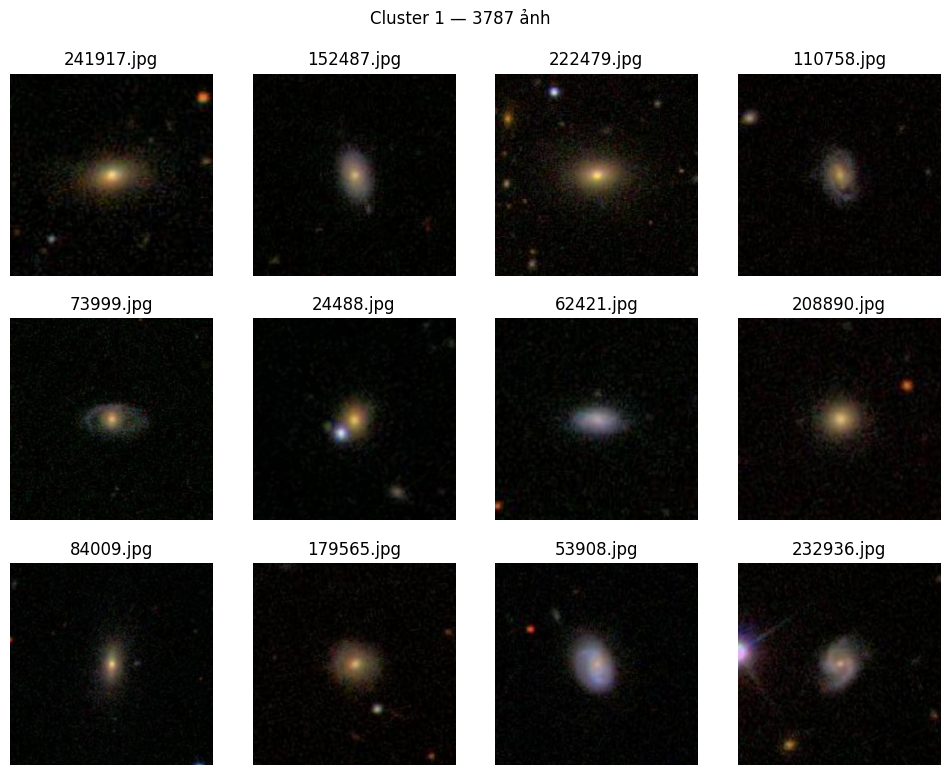

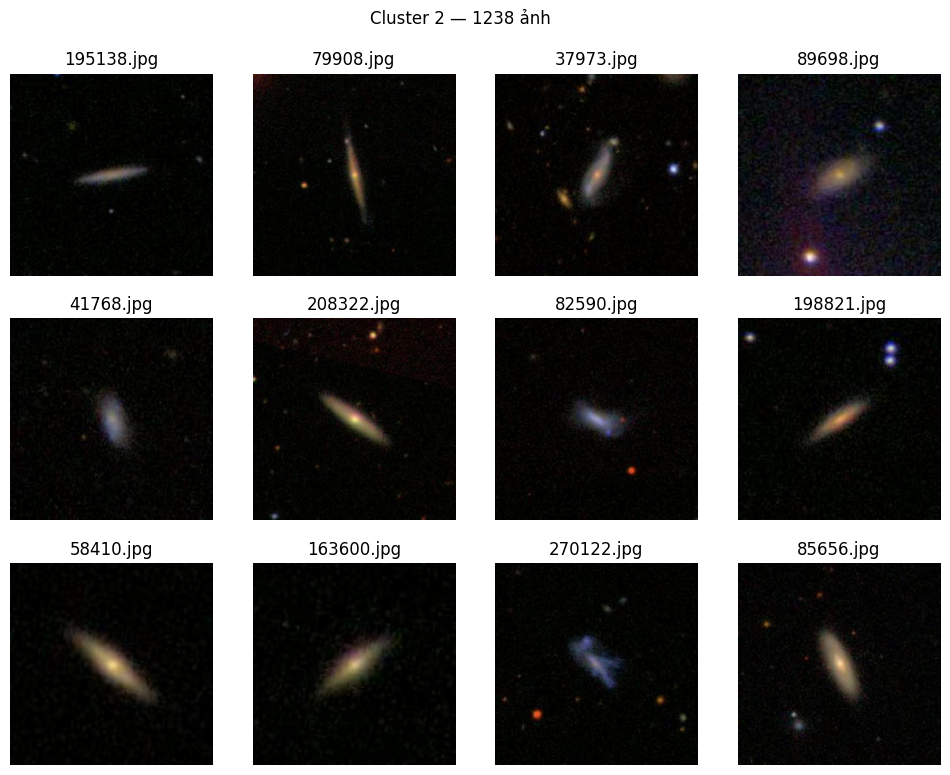

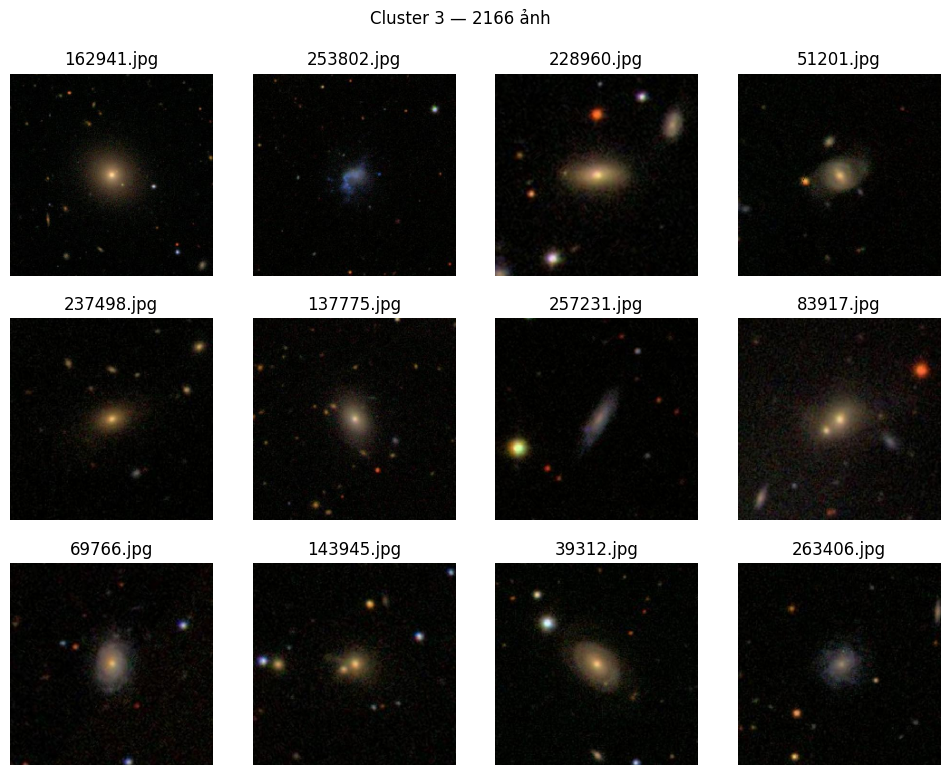

In [ ]:
import matplotlib.pyplot as plt

def show_cluster_examples(cluster_id, n=12):
    idx = np.where(labels==cluster_id)[0]
    pick = idx[:n] if len(idx)>=n else idx
    plt.figure(figsize=(12,9))
    for i,j in enumerate(pick,1):
        img = image.load_img(img_files[j], target_size=(224,224))
        plt.subplot(3,4,i); plt.imshow(img); plt.axis("off")
        plt.title(os.path.basename(img_files[j])[:10])
    plt.suptitle(f"Cluster {cluster_id} — {len(idx)} ảnh", y=0.95)
    plt.show()

for c in range(k):
    show_cluster_examples(c, n=12)


Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8948 - loss: 0.2222 - val_accuracy: 0.9860 - val_loss: 0.0396
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9758 - loss: 0.0575 - val_accuracy: 0.9830 - val_loss: 0.0322
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9766 - loss: 0.0542 - val_accuracy: 0.9830 - val_loss: 0.0350
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9858 - loss: 0.0348 - val_accuracy: 0.9880 - val_loss: 0.0253
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9903 - loss: 0.0243 - val_accuracy: 0.9920 - val_loss: 0.0298
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9884 - loss: 0.0278 - val_accuracy: 0.9840 - val_loss: 0.0432
Epoch 7/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9872 - loss: 0.0300 - val_accuracy: 0.9880 - val_loss: 0.0323
Epoch 8/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9902 - loss: 0.0232 - val_accuracy: 0

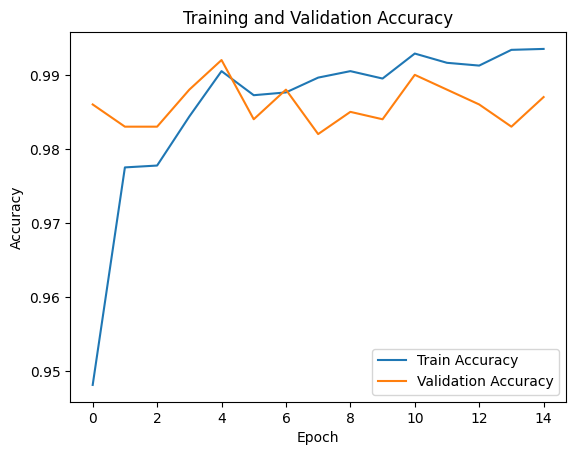

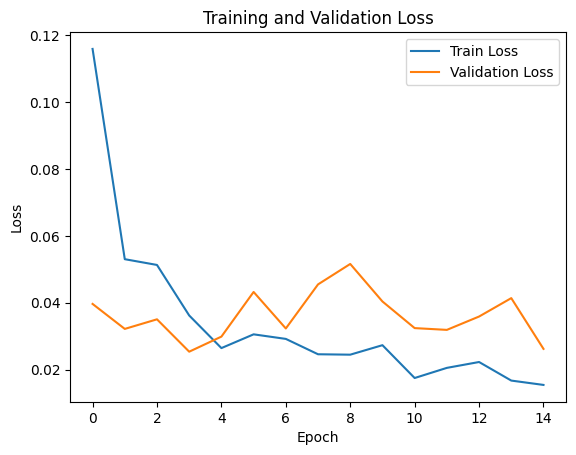

Test acc: 0.989  — classes: [np.str_('non_spiral'), np.str_('spiral')]


In [ ]:
# Ví dụ ánh xạ cụm -> nhãn nhị phân SPIRAL vs NON_SPIRAL
cluster_to_label = {0:"spiral", 1:"non_spiral", 2:"non_spiral", 3:"non_spiral"}
y_text = np.array([cluster_to_label[c] for c in labels])
classes = sorted(np.unique(y_text))
class_to_id = {c:i for i,c in enumerate(classes)}
y = np.array([class_to_id[c] for c in y_text])

# Chia tập (80/10/10)
from sklearn.model_selection import train_test_split
Xtr, Xtmp, ytr, ytmp, ftr, ftmp = train_test_split(embeds, y, img_files, test_size=0.2, random_state=42, stratify=y)
Xval, Xte,  yval, yte, fval, fte   = train_test_split(Xtmp, ytmp, ftmp, test_size=0.5, random_state=42, stratify=ytmp)

# Classifier nhỏ (nhận đầu vào là embedding 1280-d của MobileNetV2)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(embeds.shape[1],))
x = layers.Dense(256, activation="relu")(inputs)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
clf = keras.Model(inputs, outputs)
clf.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = clf.fit(Xtr, ytr, validation_data=(Xval,yval), epochs=15, batch_size=64, verbose=1)

# === Plot Accuracy ===
plt.plot(hist.history['accuracy'], label='Train Accuracy')
plt.plot(hist.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# === Plot Loss ===
plt.plot(hist.history['loss'], label='Train Loss')
plt.plot(hist.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Đánh giá
te_loss, te_acc = clf.evaluate(Xte, yte, verbose=0)
print("Test acc:", round(te_acc,4), " — classes:", classes)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


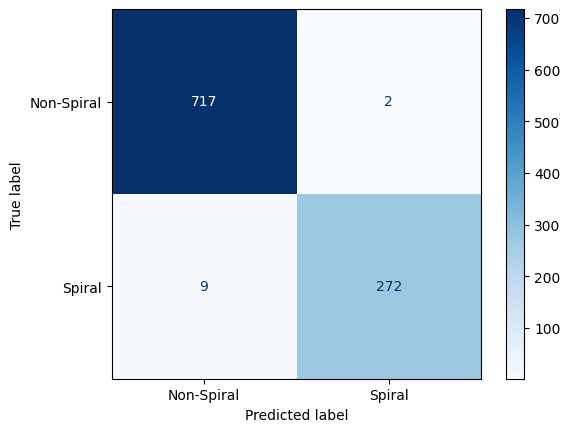

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict on test set
y_pred = clf.predict(Xte)
y_pred_classes = np.argmax(y_pred, axis=1)

# Confusion matrix
cm = confusion_matrix(yte, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Spiral', 'Spiral'])
disp.plot(cmap=plt.cm.Blues)
plt.show()


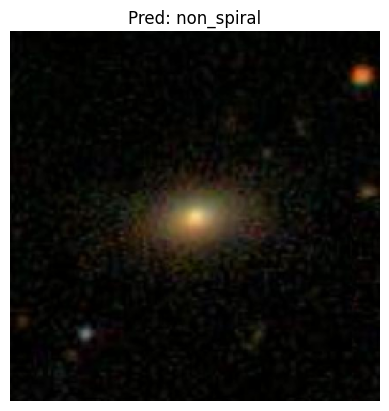

{np.str_('non_spiral'): np.float32(0.992), np.str_('spiral'): np.float32(0.008)}


In [ ]:
def predict_path(p):
    # embed ảnh -> dự đoán
    img = image.load_img(p, target_size=IMG_SIZE)
    arr = image.img_to_array(img)[None,...]
    arr = preprocess_input(arr)
    emb = base.predict(arr, verbose=0)
    prob = clf.predict(emb, verbose=0)[0]
    pred = classes[int(np.argmax(prob))]
    plt.imshow(img); plt.axis("off"); plt.title(f"Pred: {pred}")
    plt.show()
    print(dict(zip(classes, np.round(prob,3))))

predict_path(img_files[0])


In [ ]:
import os, json, numpy as np, pandas as pd, pickle
from pathlib import Path

EXP = Path("/content/export")
EXP.mkdir(parents=True, exist_ok=True)

# 1.1) Lưu mô hình phân loại (chọn cái bạn đã huấn luyện)
try:
    clf.save(EXP / "galaxy_classifier.h5")          # nếu bạn dùng classifier trên embeddings
except:
    model.save(EXP / "galaxy_classifier.h5")        # nếu bạn fine-tune MobileNetV2 end-to-end


In [ ]:
# 1.2) Lưu tên lớp (ví dụ: ['non_spiral','spiral'])
np.save(EXP / "class_names.npy", np.array(classes))


In [ ]:
# 1.3) (tùy chọn) Lưu thông tin gom cụm/KMeans + PCA (để tái sử dụng)
try:
    with open(EXP / "kmeans.pkl", "wb") as f: pickle.dump(kmeans, f)
    with open(EXP / "pca.pkl", "wb") as f: pickle.dump(pca, f)
except:
    pass

In [ ]:
# 1.4) (tùy chọn) Lưu ánh xạ cụm -> nhãn nếu bạn có bước B5
try:
    json.dump(cluster_to_label, open(EXP / "cluster_to_label.json","w"))
except:
    pass

In [ ]:
# 1.5) (tùy chọn) Lưu danh sách ảnh + nhãn cụm để báo cáo
try:
    pd.DataFrame({"path": img_files, "cluster": labels}).to_csv(EXP/"clusters.csv", index=False)
except:
    pass

print("Saved to:", EXP)

Saved to: /content/export


In [ ]:
import os, json, numpy as np, pandas as pd, pickle
from pathlib import Path
from tensorflow import keras  # để save/load dạng .keras nếu cần

EXP = Path("/content/export")
EXP.mkdir(parents=True, exist_ok=True)

# 1.1) Lưu mô hình (ưu tiên .keras; kèm .h5 dự phòng)
# - Nếu bạn train classifier trên embedding => biến 'clf' tồn tại
# - Nếu bạn fine-tune end-to-end => biến 'model' tồn tại
saved_any = False
for name in ["clf", "model"]:
    if name in globals() and globals()[name] is not None:
        mdl = globals()[name]
        # Lưu định dạng mới .keras (khuyến nghị)
        mdl.save(EXP / "galaxy_classifier.keras")
        # Lưu thêm .h5 để dự phòng (legacy)
        try:
            mdl.save(EXP / "galaxy_classifier.h5")
        except Exception as e:
            print("WARN: không lưu được .h5 (không sao):", e)
        saved_any = True
        break

if not saved_any:
    raise RuntimeError("Không tìm thấy biến mô hình ('clf' hoặc 'model'). Hãy chắc là bạn đã train xong.")

# 1.2) Lưu tên lớp
np.save(EXP / "class_names.npy", np.array(classes))

# 1.3) (tùy chọn) Lưu KMeans/PCA nếu có
try:
    if 'kmeans' in globals():
        with open(EXP / "kmeans.pkl", "wb") as f: pickle.dump(kmeans, f)
    if 'pca' in globals():
        with open(EXP / "pca.pkl", "wb") as f: pickle.dump(pca, f)
except Exception as e:
    print("WARN: không lưu được kmeans/pca:", e)

# 1.4) (tùy chọn) Lưu ánh xạ cụm -> nhãn
try:
    if 'cluster_to_label' in globals():
        with open(EXP / "cluster_to_label.json","w") as f:
            json.dump(cluster_to_label, f)
except Exception as e:
    print("WARN: không lưu được cluster_to_label:", e)

# 1.5) (tùy chọn) Lưu danh sách ảnh + nhãn cụm để báo cáo
try:
    if 'img_files' in globals() and 'labels' in globals():
        pd.DataFrame({"path": img_files, "cluster": labels}).to_csv(EXP/"clusters.csv", index=False)
except Exception as e:
    print("WARN: không lưu được clusters.csv:", e)

print("Saved to:", EXP)


Saved to: /content/export


In [ ]:
readme = """
# Galaxy Morphology Mini-Project (Student Pack)

## Cách chạy (local)
1) Cài Python 3.9+ và các gói:
   pip install tensorflow==2.15.0 numpy pillow matplotlib

2) Dự đoán 1 ảnh:
   python predict.py --model galaxy_classifier.keras --classes class_names.npy --image <duong_dan_anh.jpg>

## Ghi chú
- Nếu mô hình bạn lưu là classifier trên embedding, script đã tự nhúng MobileNetV2 để trích đặc trưng trước khi dự đoán.
- Nếu mô hình là end-to-end (nhận ảnh vào trực tiếp), script cũng tự nhận biết.
"""
open("/content/export/README.txt","w").write(readme)


499

In [ ]:
!zip -rq /content/galaxy_project_export.zip /content/export


In [ ]:
from google.colab import files
files.download("/content/galaxy_project_export.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>